# Parte Comum: Passada 1 (K-Means sobre o dataset Obesity)

Agrupamos as pessoas do dataset **Obesity (UCI 544)** com K-Means usando só as variáveis numéricas, **sem olhar o rótulo** `NObeyesdad`. Só no final comparamos os grupos com a classe real.

A lógica fica em `src/parte_comum/` (com testes em `tests/`); este notebook só chama as funções e mostra os resultados.

In [1]:
# [IA] Claude Code – importação das bibliotecas e das funções de src/parte_comum
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RAIZ / 'src'))

from parte_comum.avaliacao import avaliar
from parte_comum.clustering import (
    ajustar_kmeans, aplicar_mapa, k_cotovelo, kmeans_inercias, mapear_clusters, projetar_2d,
)
from parte_comum.preprocessing import ALVO, NUMERICAS, carregar_obesity, padronizar
from parte_comum.visualizacao import plotar_clusters, plotar_cotovelo

SAIDA = RAIZ / 'out' / 'parte_comum'
SAIDA.mkdir(parents=True, exist_ok=True)
SEMENTE = 42

## 1. Padronizar as variáveis

A padronização é importante no K-Means. Esse algoritmo utiliza a distância euclidiana para calcular a proximidade entre os dados e formar os grupos. Como nossas variáveis possuem escalas diferentes, como altura, peso e idade, sem a padronização algumas variáveis poderiam ter muito mais influência no cálculo das distâncias do que outras. Por isso utilizamos o StandardScaler, que deixa as variáveis com média próxima de zero e desvio padrão igual a um, fazendo com que todas tenham uma participação mais equilibrada na formação dos grupos.


**Escolha das variáveis (decisão do grupo):** Escolhemos as oito variáveis numéricas porque o K-Means utiliza cálculos de distância para formar os grupos. As variáveis representam características físicas, idade e hábitos relacionados à alimentação, consumo de água e atividade física. As variáveis categóricas continuam sendo analisadas na EDA, mas não entram no agrupamento.


In [2]:
# [IA] Claude Code – leitura do Obesity e padronização z-score das variáveis numéricas
df = carregar_obesity(RAIZ / 'data' / 'parte_comum' / 'obesity.csv')
X = padronizar(df, NUMERICAS)
print(f'{len(df)} linhas, {len(NUMERICAS)} variáveis numéricas')
X.describe().loc[['mean', 'std']].round(3)

2111 linhas, 8 variáveis numéricas


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
mean,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. K-Means com k de 2 a 10 e Método do Cotovelo

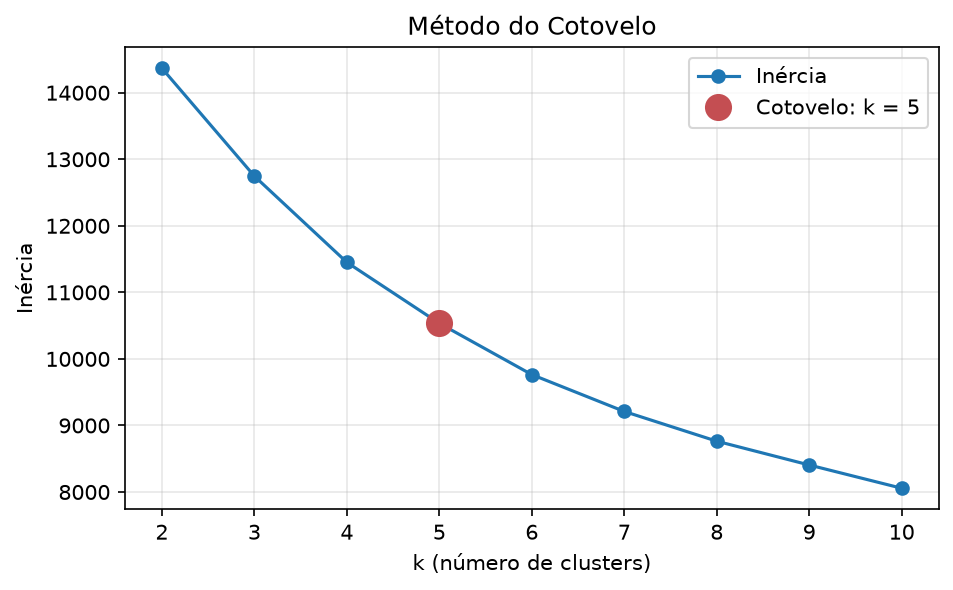

,inercia
2,14368.0
3,12746.7
4,11451.6
5,10534.9
6,9764.3
7,9210.4
8,8763.7
9,8406.0
10,8056.6


In [3]:
# [IA] Claude Code – inércia do K-Means para k de 2 a 10 e gráfico do Método do Cotovelo
inercias = kmeans_inercias(X, range(2, 11), random_state=SEMENTE)
K = k_cotovelo(inercias)
fig = plotar_cotovelo(inercias, k_escolhido=K)
fig.savefig(SAIDA / 'passada1_cotovelo.png', dpi=150, bbox_inches='tight')
display(Image(filename=SAIDA / 'passada1_cotovelo.png'))
inercias.round(1).to_frame()

**Escolha do k (decisão do grupo):** Escolhemos k = 5 pelo método do cotovelo, utilizando o critério da maior distância até a reta entre os extremos do gráfico. A curva não apresenta um cotovelo muito definido, e o valor k = 6 também fica próximo, mas o critério utilizado apontou k = 5. O critério está implementado na função `k_cotovelo` (`src/parte_comum/clustering.py`), e o ponto escolhido aparece em vermelho no gráfico.


In [4]:
# [IA] Claude Code – K-Means com o k sugerido pelo cotovelo
print(f'k escolhido pelo cotovelo: {K}')
labels = ajustar_kmeans(X, k=K, random_state=SEMENTE)
pd.Series(labels).value_counts().sort_index().to_frame('amostras')

k escolhido pelo cotovelo: 5


,amostras
0,295
1,618
2,480
3,416
4,302


## 3. Visualizar os grupos

Projetamos as 8 variáveis padronizadas em 2 componentes principais (PCA) só para desenhar. O agrupamento em si foi feito nas 8 dimensões.

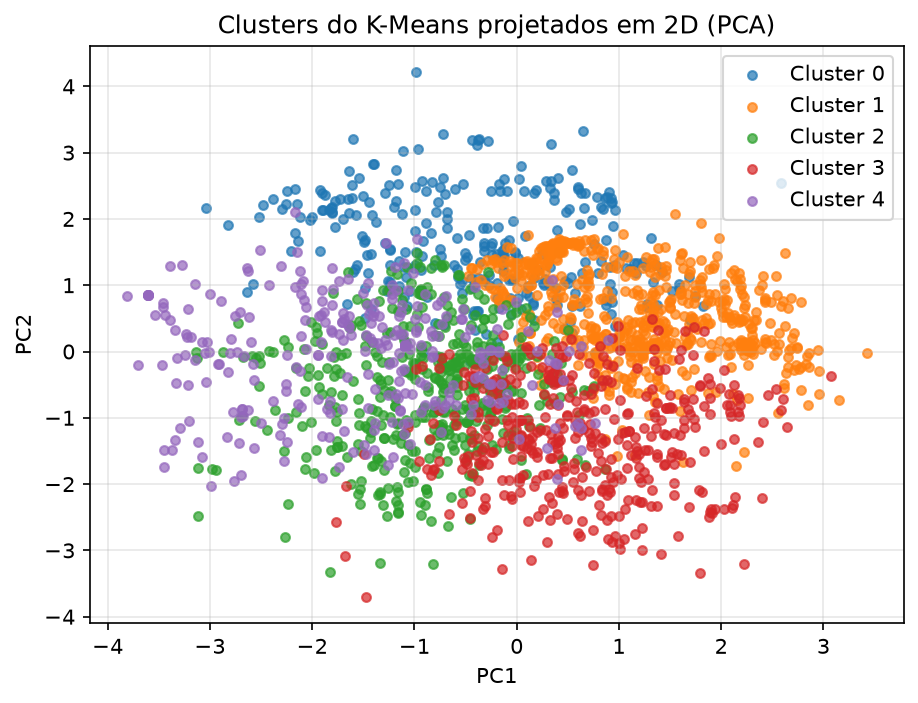

In [5]:
# [IA] Claude Code – projeção PCA em 2D e gráfico dos clusters
proj = projetar_2d(X, random_state=SEMENTE)
fig = plotar_clusters(proj, labels)
fig.savefig(SAIDA / 'passada1_clusters_pca.png', dpi=150, bbox_inches='tight')
display(Image(filename=SAIDA / 'passada1_clusters_pca.png'))

## 4. Mapear cada cluster para a classe majoritária

K-Means não sabe o nome das classes. Rotulamos cada cluster com a classe real mais frequente dentro dele (empate: ordem alfabética, para ser determinístico).

In [6]:
# [IA] Claude Code – mapeamento de cada cluster para a classe majoritária
mapa = mapear_clusters(labels, df[ALVO])
previstas = aplicar_mapa(labels, mapa)
pd.Series(mapa, name='classe majoritária').rename_axis('cluster').to_frame()

,classe majoritária
cluster,
0,Obesity_Type_I
1,Obesity_Type_III
2,Normal_Weight
3,Insufficient_Weight
4,Overweight_Level_I


## 5. Matriz de confusão, acurácia, precisão e recall

In [7]:
# [IA] Claude Code – matriz de confusão, acurácia, precisão e recall
r = avaliar(df[ALVO], previstas)
r['matriz_confusao'].to_csv(SAIDA / 'passada1_matriz_confusao.csv')
print(f"Acurácia: {r['acuracia']:.3f}")
print(f"Precisão (macro): {r['precisao']:.3f}")
print(f"Recall (macro): {r['recall']:.3f}")
r['matriz_confusao']

Acurácia: 0.334
Precisão (macro): 0.225
Recall (macro): 0.330


,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Insufficient_Weight,131,84,3,0,0,54,0
Normal_Weight,98,123,15,0,0,51,0
Obesity_Type_I,50,71,87,0,81,62,0
Obesity_Type_II,0,3,57,0,208,29,0
Obesity_Type_III,0,28,0,0,296,0,0
Overweight_Level_I,76,94,46,0,5,69,0
Overweight_Level_II,61,77,87,0,28,37,0


## Conclusão

Na Passada 1, o K-Means foi testado com valores de k entre 2 e 10, utilizando o Método do Cotovelo. A inércia diminuiu conforme aumentava o número de grupos, mas a curva não apresentou um cotovelo muito claro. Pelo critério da maior distância até a reta, o valor escolhido foi k = 5, embora k = 6 tenha ficado próximo. Com cinco grupos, algumas classes reais ficaram misturadas e duas delas (Obesity_Type_II e Overweight_Level_II) não apareceram como classe majoritária em nenhum cluster. A acurácia foi de 33,4%, mostrando que os grupos encontrados representam apenas parcialmente as classes originais.
